First, we will find the slope and intercept using OLS method and then we will code `Gradient Descent` from scratch.
We will get almost same slope and intercept for both these methods.

In [4]:
from sklearn.datasets import make_regression

import matplotlib.pyplot as plt
import numpy as np

In [3]:
x, y = make_regression(
    n_samples = 4,
    n_features = 1,
    n_targets = 1,
    n_informative = 1,
    noise = 80,
    random_state = 1
)

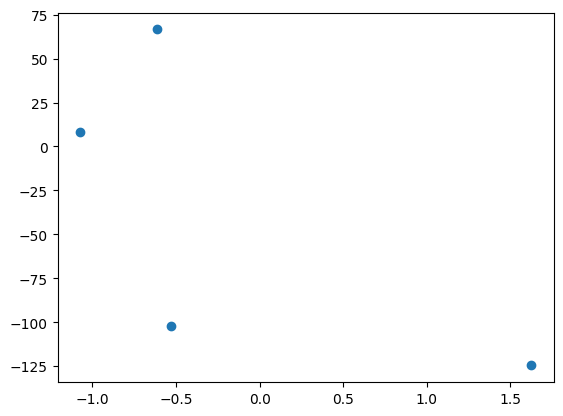

In [5]:
plt.scatter(x, y)

# OLS Method

In [29]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(x, y)

slope = lr_model.coef_[0]    # model.coef_ returns list of slopes. Here we have only one slope. So, slope[0]
intercept = lr_model.intercept_   # model.intercept_ returns a scalar value bcz ther will be always 1 intercept not more than 1

print(f'''Slope(m)= {slope}
Intercept(c) = {intercept}''')

Slope(m)= -50.61708584513232
Intercept(c) = -45.44115263199092


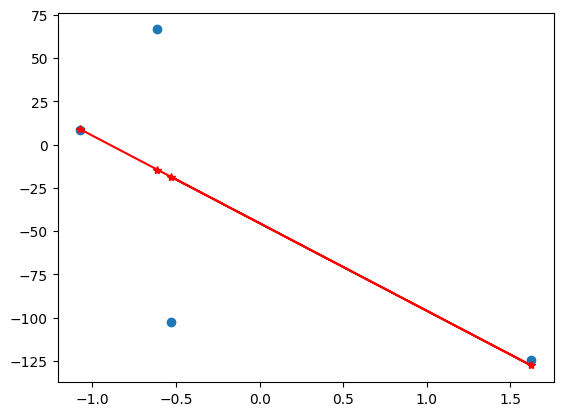

In [30]:
plt.scatter(x, y)
plt.plot(x, lr_model.predict(x), color = 'red', marker = '*')

# Let's apply `Gradient Descent` assuming 
1. Slope is constant and 
2. Initial random value of c = 0

In [126]:
# Assume slope is constant
m = slope
m

-50.61708584513232

In [127]:
# y_pred = mx+c
# We took initial random value of c = 0

y_pred = m*(x) + 0

y_pred

array([[ 54.31054486],
       [ 30.96532691],
       [-82.21962871],
       [ 26.73451493]])

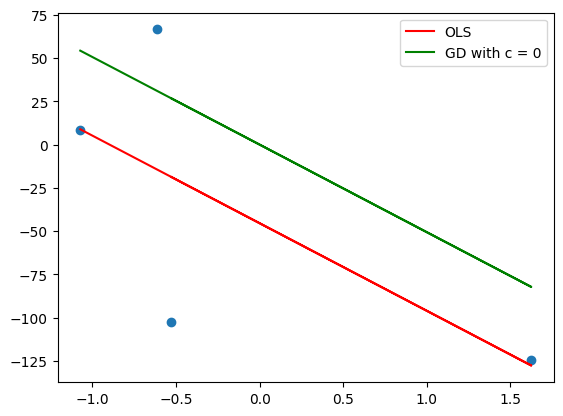

In [128]:
plt.scatter(x, y)
plt.plot(x, lr_model.predict(x), color = 'red', label = 'OLS')
plt.plot(x, y_pred, color = 'green', label = "GD with c = 0")
plt.legend()
plt.show()

# `C1 = 0`, Let's find `C2`

`Formula`:
* Cnew = Cold - (lr) (Slope at Cold)
* Slope at C = -2* Sum(y-mx-c)

`We already have `m` stored in variable `slope`
So, `Slope at c = (-2) Sum(y - slope(x) - c)

In [129]:
c_old = 0

slope_c_0 = (-2)*(np.sum(y.ravel() - (m)*(x.ravel()) - c_old))
slope_c_0
print(f"Slope at {c_old}: {slope_c_0}")
# learning rate = 0.01
c_new = c_old - 0.01*(slope_c_0)
print(f"C_new: {c_new}")

Slope at 0: 363.52922105592734
C_new: -3.6352922105592733


[ 50.67525265  27.3300347  -85.85492093  23.09922271]


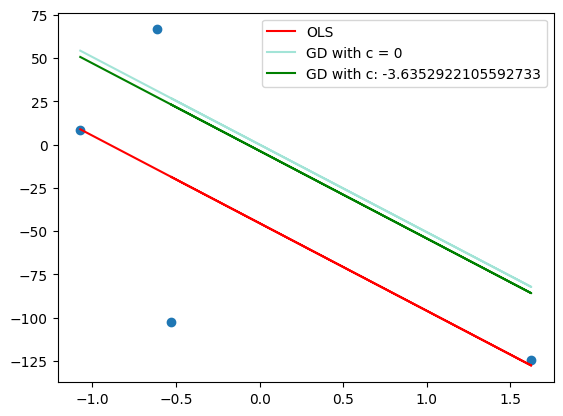

In [130]:
y_pred_1 = (m*x + c_new).ravel()
print(y_pred_1)


plt.scatter(x, y)
plt.plot(x, lr_model.predict(x), color = 'red', label = 'OLS')
plt.plot(x, y_pred, color='#A3E4D7', label = "GD with c = 0")
plt.plot(x, y_pred_1, color = 'green', label = f"GD with c: {c_new}")
plt.legend()
plt.show()

# Iteration 2:
* Cold = Cnew
* Slope_c_new = (-2)*(np.sum(y.ravel() - (m)*(x.ravel()) - cold))

In [131]:
c_old = c_new

slope_c_old = (-2)*np.sum(y.ravel() - (m.ravel())*(x.ravel()) - c_old.ravel())
print(f"Slope at {c_old}: {slope_c_old}")

c_new = c_old - 0.01*(slope_c_old)
print(f"C_new: {c_new}")

Slope at -3.6352922105592733: 334.44688337145317
C_new: -6.979761044273805


[ 47.33078381  23.98556586 -89.19938976  19.75475388]


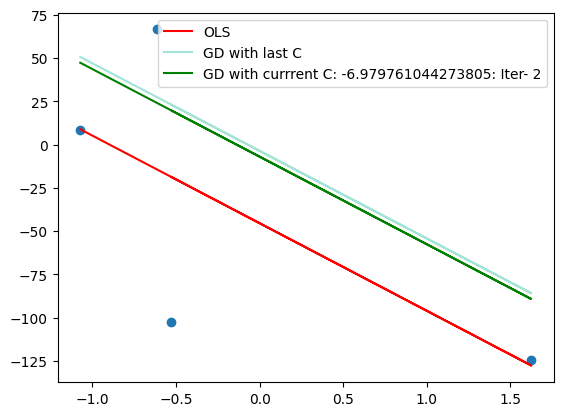

In [132]:
y_pred_2 = (m*x + c_new).ravel()
print(y_pred_2)


plt.scatter(x, y)
plt.plot(x, lr_model.predict(x), color = 'red', label = 'OLS')
plt.plot(x, y_pred_1, color='#A3E4D7', label = "GD with last C")
plt.plot(x, y_pred_2, color = 'green', label = f"GD with currrent C: {c_new}: Iter- 2")
plt.legend()
plt.show()

# Iteration 3
* Cold = Cnew
* Slope_c_new = (-2)*(np.sum(y.ravel() - (m)*(x.ravel()) - cold))


In [133]:
c_old = c_new

slope_c_old = (-2)*np.sum(y.ravel() - (m.ravel())*(x.ravel()) - c_old.ravel())
print(f"Slope at {c_old}: {slope_c_old}")

c_new = c_old - 0.01*(slope_c_old)
print(f"C_new: {c_new}")

Slope at -6.979761044273805: 307.6911327017369
C_new: -10.056672371291175


[ 44.25387249  20.90865453 -92.27630109  16.67784255]


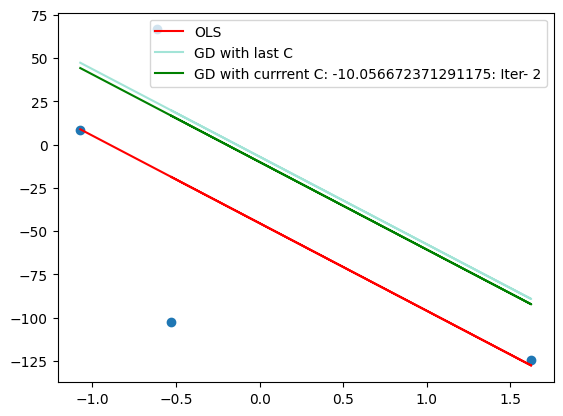

In [134]:
y_pred_3 = (m*x + c_new).ravel()
print(y_pred_3)


plt.scatter(x, y)
plt.plot(x, lr_model.predict(x), color = 'red', label = 'OLS')
plt.plot(x, y_pred_2, color='#A3E4D7', label = "GD with last C")
plt.plot(x, y_pred_3, color = 'green', label = f"GD with currrent C: {c_new}: Iter- 2")
plt.legend()
plt.show()

In [ ]:
# Here, we are moving very slowly, so let's increase our learning rate somewhat
# lr = 0.02

# Iteration 3
* Cold = Cnew
* Slope_c_new = (-2)*(np.sum(y.ravel() - (m)*(x.ravel()) - cold))
* lr = 0.02

In [137]:
c_old = c_new

slope_c_old = (-2)*np.sum(y.ravel() - (m.ravel())*(x.ravel()) - c_old.ravel())
print(f"Slope at {c_old}: {slope_c_old}")

c_new = c_old - 0.02*(slope_c_old)
print(f"C_new: {c_new}")

Slope at -10.056672371291175: 283.07584208559797
C_new: -15.718189213003134


[ 38.59235564  15.24713769 -97.93781793  11.01632571]


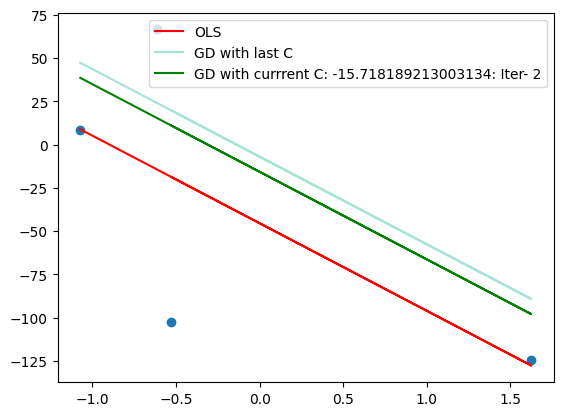

In [138]:
y_pred_3 = (m*x + c_new).ravel()
print(y_pred_3)


plt.scatter(x, y)
plt.plot(x, lr_model.predict(x), color = 'red', label = 'OLS')
plt.plot(x, y_pred_2, color='#A3E4D7', label = "GD with last C")
plt.plot(x, y_pred_3, color = 'green', label = f"GD with currrent C: {c_new}: Iter- 2")
plt.legend()
plt.show()

-9.088230526398183
-16.35881494751673
-22.175282484411568
-26.82845651392744
-30.550995737540134
-33.52902711643029
-35.91145221954242
-37.81739230203212
-39.34214436802388
-40.56194602081729
-41.53778734305202
-42.3184604008398
-42.94299884707002
-43.442629604054204
-43.84233420964155
-44.162097894111426
-44.41790884168732
-44.62255759974804
-44.786276606196616
-44.91725181135548
-45.02203197548256
-45.10585610678423
-45.17291541182557
-45.22656285585864
-45.269480811085096


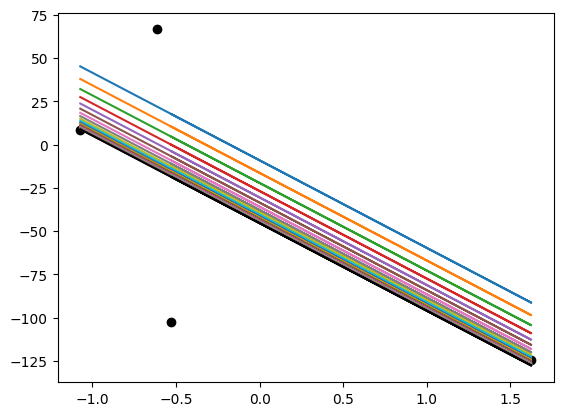

In [164]:
# Let's run a loop and observe how things are working

c = 0
m = m
lr = 0.025
epochs = 25

for i in range(epochs):
    # Calculate slope at current value of c
    slope = (-2)*np.sum(y.ravel() - (m)*(x.ravel()) - c)

    # Update c
    c = c - (lr)*(slope)

    # Predict
    y_pred = (m)*(x) + c

    # Plot graph
    plt.plot(x, y_pred)
    print(c)

plt.scatter(x, y, color = 'black')
plt.plot(x, lr_model.predict(x), color = (0,0,0))